## Assignment 8: Using Unsupervised Machine Learning to Discover Climate Zones

In this homework assignment, you will explore some common clustering methods, including K-Means clustering and Gaussian Mixture Models. 

You'll apply these clustering algorithms to the problem of classifying climate zones over the continental United States. The Köppen-Geiger Climate Zones are a climate classification system based on precipitation and temperature (https://www.noaa.gov/jetstream/global/climate-zones/jetstream-max-addition-k-ppen-geiger-climate-subdivisions). You'll use unsupervised machine learning to discover similar climate zones using the climatological averages for temperature and precipitation.

## The data sets
You'll use climatological data over the continental US, specifically average monthly precipitation and temperature records for the years 1901 to 2000 from NOAA that can be found [here](https://www.ncei.noaa.gov/products/land-based-station/us-climate-normals). The code in question 1 downloads the two NetCDF files the first time you run it and saves them next to this notebook. After that it skips the download.

## Part 1: Load and prepare the climatological data

1) The code below is given. Run it to download the NetCDF files for the climatological temperature and precipitation datasets for the continental US, if they are not already in this folder, and open them with `xarray`. The download can take a few minutes.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# Download once if the files are not already alongside this notebook.
import os, urllib.request
BASE = ("https://www.ncei.noaa.gov/data/oceans/archive/arc0196/0248762/1.1/"
        "data/0-data/")
for fname in ["tavg-1901_2000-monthly-normals-v1.0.nc",
              "prcp-1901_2000-monthly-normals-v1.0.nc"]:
    if not os.path.exists(fname):
        print("downloading", fname, "(268 MB)...")
        urllib.request.urlretrieve(BASE + fname, fname)

temp = xr.open_dataset("tavg-1901_2000-monthly-normals-v1.0.nc")
prec = xr.open_dataset("prcp-1901_2000-monthly-normals-v1.0.nc")

In [2]:
prec

<xarray.Dataset> Size: 281MB
Dimensions:        (time: 12, lat: 596, lon: 1385, seasons: 4)
Coordinates:
  * time           (time) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat            (lat) float32 2kB 49.35 49.31 49.27 ... 24.65 24.6 24.56
  * lon            (lon) float32 6kB -124.7 -124.6 -124.6 ... -67.06 -67.02
  * seasons        (seasons) int32 16B 1 2 3 4
Data variables: (12/15)
    mlyprcp_norm   (time, lat, lon) float32 40MB ...
    mlyprcp_std    (time, lat, lon) float32 40MB ...
    mlyprcp_min    (time, lat, lon) float32 40MB ...
    mlyprcp_max    (time, lat, lon) float32 40MB ...
    mlyprcp_flag   (time, lat, lon) float32 40MB ...
    seasprcp_norm  (seasons, lat, lon) float32 13MB ...
    ...             ...
    seasprcp_flag  (seasons, lat, lon) float32 13MB ...
    annprcp_norm   (lat, lon) float32 3MB ...
    annprcp_std    (lat, lon) float32 3MB ...
    annprcp_min    (lat, lon) float32 3MB ...
    annprcp_max    (lat, lon) float32 3MB ...
    annprcp_flag   (lat, lon) float32 3MB ...
Attributes: (12/28)
    date_created:                2021-09-16 08:30:01
    date_modified:               2021-09-16 08:30:01
    Conventions:                 CF-1.6, ACDD-1.3
    ncei_template_version:       NCEI_NetCDF_Grid_Template_v2.0
    title:                       1991-2020 Normals
    naming_authority:            gov.noaa.ncei
    ...                          ...
    time_coverage_resolution:    1 month
    program:                     Center for Weather and Climate/Climate Scien...
    geospatial_lat_resolution:   0.04167 degree
    geospatial_lon_resolutioin:  0.04167 degree
    platform:                    station
    references:                  nClimGrid Monthly (Vose et al. 2014), https:...

In [3]:
temp

<xarray.Dataset> Size: 281MB
Dimensions:        (time: 12, lat: 596, lon: 1385, seasons: 4)
Coordinates:
  * time           (time) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat            (lat) float32 2kB 49.35 49.31 49.27 ... 24.65 24.6 24.56
  * lon            (lon) float32 6kB -124.7 -124.6 -124.6 ... -67.06 -67.02
  * seasons        (seasons) int32 16B 1 2 3 4
Data variables: (12/15)
    mlytavg_norm   (time, lat, lon) float32 40MB ...
    mlytavg_std    (time, lat, lon) float32 40MB ...
    mlytavg_min    (time, lat, lon) float32 40MB ...
    mlytavg_max    (time, lat, lon) float32 40MB ...
    mlytavg_flag   (time, lat, lon) float32 40MB ...
    seastavg_norm  (seasons, lat, lon) float32 13MB ...
    ...             ...
    seastavg_flag  (seasons, lat, lon) float32 13MB ...
    anntavg_norm   (lat, lon) float32 3MB ...
    anntavg_std    (lat, lon) float32 3MB ...
    anntavg_min    (lat, lon) float32 3MB ...
    anntavg_max    (lat, lon) float32 3MB ...
    anntavg_flag   (lat, lon) float32 3MB ...
Attributes: (12/28)
    date_created:                2021-09-16 08:30:01
    date_modified:               2021-09-16 08:30:01
    Conventions:                 CF-1.6, ACDD-1.3
    ncei_template_version:       NCEI_NetCDF_Grid_Template_v2.0
    title:                       1991-2020 Normals
    naming_authority:            gov.noaa.ncei
    ...                          ...
    time_coverage_resolution:    1 month
    program:                     Center for Weather and Climate/Climate Scien...
    geospatial_lat_resolution:   0.04167 degree
    geospatial_lon_resolutioin:  0.04167 degree
    platform:                    station
    references:                  nClimGrid Monthly (Vose et al. 2014), https:...

2) Make a plot of the monthly average precipitation in January over the Continental US.

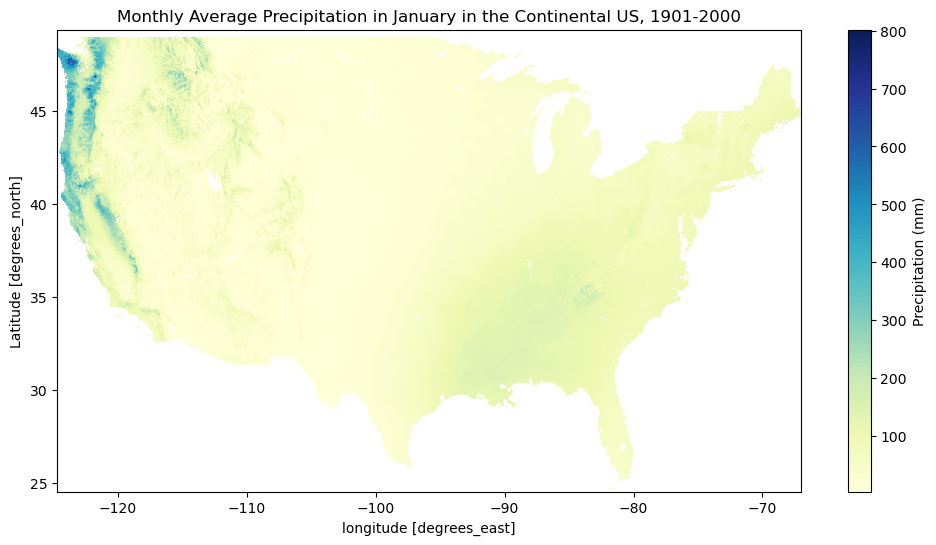

In [4]:
jan_prec_avg = prec['mlyprcp_norm'].sel(time=1)

plt.figure(figsize = (12,6))
jan_prec_avg.plot(cmap="YlGnBu", cbar_kwargs = {"label":"Precipitation (mm)"})
plt.title("Monthly Average Precipitation in January in the Continental US, 1901-2000")
plt.show()

3. Make a plot of the monthly average temperature in August over the Continent US.

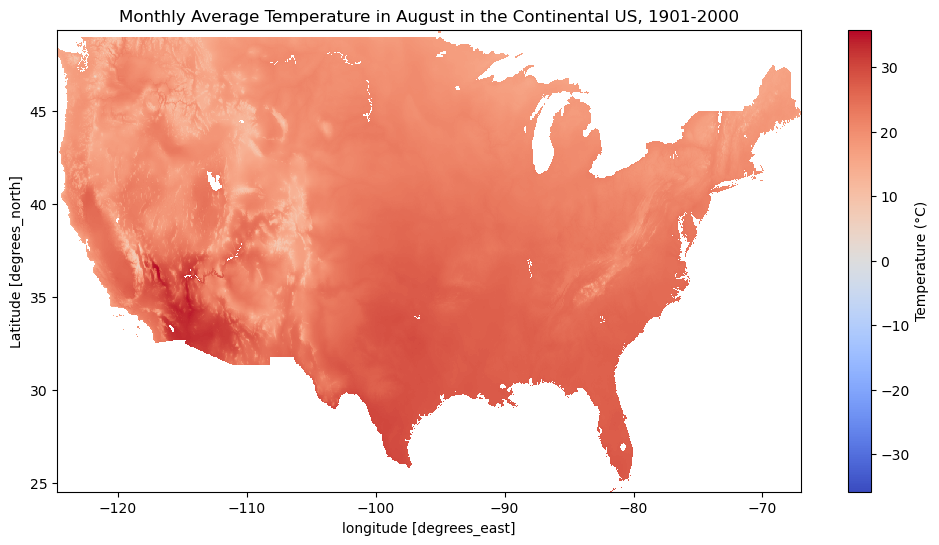

In [5]:
jan_temp_avg = temp['mlytavg_norm'].sel(time=8)

plt.figure(figsize = (12,6))
jan_temp_avg.plot(cmap="coolwarm", center=0, cbar_kwargs = {"label":"Temperature (°C)"})
plt.title("Monthly Average Temperature in August in the Continental US, 1901-2000")
plt.show()

To identify climatological zones across the continental US, you will use the 12 monthly average temperature values and the 12 monthly average precipitation values as input features for clustering algorithms. Each latitude and longitude point will be treated as a single sample with 24 features (12 for temperature and 12 for precipitation).

4) First, extract the values for "mlytavg_norm" from the temperature and precipitation NetCDF files and store them in NumPy arrays named `avgtemp` and `avgprec`, respectively.

In [6]:
avgprec = prec['mlyprcp_norm'].values
avgtemp = temp['mlytavg_norm'].values

In [7]:
avgprec

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       ...,

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan

In [8]:
avgtemp

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       ...,

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan

5. Put the latitude and longitude values into numpy arrays, and use the `np.meshgrid` function to create a 2D array that gives the latitude and longitude value at each point on the map:
~~~
lat_grid, lon_grid = np.meshgrid(lats, lons, indexing="ij")
~~~
You'll use these arrays later to create labels for the latitude and longitude points associated with each sample.

In [9]:
lats = temp['lat'].values
lons = temp['lon'].values
lat_grid, lon_grid = np.meshgrid(lats, lons, indexing="ij")

In [10]:
lat_grid

array([[49.3542  , 49.3542  , 49.3542  , ..., 49.3542  , 49.3542  ,
        49.3542  ],
       [49.312534, 49.312534, 49.312534, ..., 49.312534, 49.312534,
        49.312534],
       [49.270866, 49.270866, 49.270866, ..., 49.270866, 49.270866,
        49.270866],
       ...,
       [24.645866, 24.645866, 24.645866, ..., 24.645866, 24.645866,
        24.645866],
       [24.6042  , 24.6042  , 24.6042  , ..., 24.6042  , 24.6042  ,
        24.6042  ],
       [24.562532, 24.562532, 24.562532, ..., 24.562532, 24.562532,
        24.562532]], dtype=float32)

In [11]:
lon_grid

array([[-124.6875  , -124.645836, -124.604164, ...,  -67.104164,
         -67.0625  ,  -67.020836],
       [-124.6875  , -124.645836, -124.604164, ...,  -67.104164,
         -67.0625  ,  -67.020836],
       [-124.6875  , -124.645836, -124.604164, ...,  -67.104164,
         -67.0625  ,  -67.020836],
       ...,
       [-124.6875  , -124.645836, -124.604164, ...,  -67.104164,
         -67.0625  ,  -67.020836],
       [-124.6875  , -124.645836, -124.604164, ...,  -67.104164,
         -67.0625  ,  -67.020836],
       [-124.6875  , -124.645836, -124.604164, ...,  -67.104164,
         -67.0625  ,  -67.020836]], dtype=float32)

6. Use the `np.isnan` function to create a mask that gives a value of 1 where there is data and a value of 0 where there is no data in the 2D array of the precipitation and temperature maps over the continental US. This mask should have the same dimensions as latitude by longitude. Hint: `np.isnan` returns 1 (True) if the value is `NaN`. 

In [12]:
mask = (~np.isnan(avgtemp[0])).astype('int64')
def masked_function(array):
    if array.ndim == 3:
        return array[:, mask == 1]
    elif array.ndim == 2:
        return array[mask == 1]
mask.shape

(596, 1385)

In [13]:
lat_grid.shape

(596, 1385)

In [14]:
lon_grid.shape

(596, 1385)

7. Use the mask to index the numpy arrays of `avgtemp`, `avgprec`, `lat_grid`, and `lon_grid` to create arrays called `avgtemp_masked`, `avgprec_masked`, `lat_masked`, and `lon_masked`. These arrays now should no longer have any NaN's.

In [15]:
avgtemp_masked = masked_function(avgtemp)
avgprec_masked = masked_function(avgprec)
lat_masked = masked_function(lat_grid)
lon_masked = masked_function(lon_grid)

In [16]:
avgtemp_masked

array([[-18.244795 , -18.240566 , -18.18745  , ...,  20.783154 ,
         20.774208 ,  20.767118 ],
       [-14.923623 , -14.920723 , -14.867324 , ...,  21.11292  ,
         21.105507 ,  21.094814 ],
       [ -7.086836 ,  -7.0770802,  -7.014287 , ...,  22.608477 ,
         22.59334  ,  22.582636 ],
       ...,
       [  5.3208203,   5.3255076,   5.3298926, ...,  26.372774 ,
         26.31588  ,  26.311924 ],
       [ -4.6921973,  -4.690098 ,  -4.637705 , ...,  23.532042 ,
         23.512842 ,  23.508085 ],
       [-13.976182 , -13.977998 , -13.97752  , ...,  21.418896 ,
         21.403858 ,  21.396112 ]], dtype=float32)

In [17]:
avgprec_masked

array([[ 22.603174,  22.536104,  22.55749 , ...,  51.234745,  51.096603,
         50.68712 ],
       [ 18.314892,  18.289736,  18.369024, ...,  42.39117 ,  41.99421 ,
         41.658722],
       [ 26.010614,  26.076406,  26.008896, ...,  41.936886,  42.17373 ,
         42.113995],
       ...,
       [ 39.910313,  39.94803 ,  40.04042 , ..., 137.37    , 138.01596 ,
        139.69339 ],
       [ 29.981787,  30.140253,  30.352617, ...,  45.4871  ,  45.60168 ,
         45.77623 ],
       [ 23.62586 ,  23.56    ,  23.466768, ...,  49.00636 ,  49.402794,
         49.74908 ]], dtype=float32)

In [18]:
lat_masked

array([49.3542  , 49.3542  , 49.3542  , ..., 24.562532, 24.562532,
       24.562532], dtype=float32)

In [19]:
lon_masked

array([-95.145836, -95.104164, -95.0625  , ..., -81.770836, -81.729164,
       -81.6875  ], dtype=float32)

In [20]:
np.isnan(avgtemp_masked).any()

False

In [21]:
np.isnan(avgprec_masked).any()

False

In [22]:
np.isnan(lat_masked).any()

False

In [23]:
np.isnan(lat_masked).any()

False

In [24]:
avgtemp_masked.shape

(12, 469758)

In [25]:
avgprec_masked.shape

(12, 469758)

8. `sci-kit learn` functions assume that the sample number ($n_{sample}$) is the first dimension in an array, and the features associated with a sample are in the second dimension in an array. Transpose the `avgprec_masked` and `avgtemp_masked` to get the correct ordering of dimensions. Check the shape of the arrays are now $n_{sample}$ x 12.

In [26]:
avgprec_transposed = avgprec_masked.T
avgprec_transposed.shape

(469758, 12)

In [27]:
avgprec_transposed

array([[ 22.603174,  18.314892,  26.010614, ...,  39.910313,  29.981787,
         23.62586 ],
       [ 22.536104,  18.289736,  26.076406, ...,  39.94803 ,  30.140253,
         23.56    ],
       [ 22.55749 ,  18.369024,  26.008896, ...,  40.04042 ,  30.352617,
         23.466768],
       ...,
       [ 51.234745,  42.39117 ,  41.936886, ..., 137.37    ,  45.4871  ,
         49.00636 ],
       [ 51.096603,  41.99421 ,  42.17373 , ..., 138.01596 ,  45.60168 ,
         49.402794],
       [ 50.68712 ,  41.658722,  42.113995, ..., 139.69339 ,  45.77623 ,
         49.74908 ]], dtype=float32)

In [28]:
avgtemp_transposed = avgtemp_masked.T
avgtemp_transposed.shape

(469758, 12)

In [29]:
avgtemp_transposed

array([[-18.244795 , -14.923623 ,  -7.086836 , ...,   5.3208203,
         -4.6921973, -13.976182 ],
       [-18.240566 , -14.920723 ,  -7.0770802, ...,   5.3255076,
         -4.690098 , -13.977998 ],
       [-18.18745  , -14.867324 ,  -7.014287 , ...,   5.3298926,
         -4.637705 , -13.97752  ],
       ...,
       [ 20.783154 ,  21.11292  ,  22.608477 , ...,  26.372774 ,
         23.532042 ,  21.418896 ],
       [ 20.774208 ,  21.105507 ,  22.59334  , ...,  26.31588  ,
         23.512842 ,  21.403858 ],
       [ 20.767118 ,  21.094814 ,  22.582636 , ...,  26.311924 ,
         23.508085 ,  21.396112 ]], dtype=float32)

## Part 2: Pre-process the data

9. Scale the precipitation and temperature arrays between -1 and 1. You want to do this so that all 12 months are scaled relative to the same minimum and maximum values for precipitation or temperature, respectively. You can use the `MinMaxScaler` from `sci-kit learn` (you will have to reshape the arrays to do this) or alternatively write your own function to do this scaling.

In [30]:
from sklearn.preprocessing import MinMaxScaler

def scale(array):
    reshape_array = array.reshape(-1, 1)
    scaler = MinMaxScaler(feature_range=(-1,1)).fit(reshape_array)
    X = scaler.transform(reshape_array).reshape(array.shape)
    return X

avgprec_scaled = scale(avgprec_transposed)
avgtemp_scaled = scale(avgtemp_transposed)

In [31]:
avgprec_scaled

array([[-0.9469063 , -0.9569793 , -0.9389024 , ..., -0.90625274,
        -0.9295743 , -0.9445041 ],
       [-0.94706386, -0.95703834, -0.9387479 , ..., -0.9061641 ,
        -0.9292021 , -0.94465876],
       [-0.9470136 , -0.9568521 , -0.93890643, ..., -0.9059471 ,
        -0.92870325, -0.94487774],
       ...,
       [-0.8796522 , -0.9004253 , -0.9014924 , ..., -0.6773249 ,
        -0.89315313, -0.88488656],
       [-0.8799767 , -0.90135777, -0.90093607, ..., -0.6758076 ,
        -0.892884  , -0.88395536],
       [-0.88093853, -0.9021458 , -0.9010764 , ..., -0.6718674 ,
        -0.892474  , -0.88314193]], dtype=float32)

In [32]:
avgtemp_scaled

array([[-0.99686116, -0.87718624, -0.59479594, ..., -0.14769928,
        -0.5085077 , -0.84304625],
       [-0.99670875, -0.87708175, -0.5944444 , ..., -0.14753038,
        -0.50843203, -0.84311163],
       [-0.9947948 , -0.8751576 , -0.59218174, ..., -0.14737236,
        -0.5065441 , -0.8430944 ],
       ...,
       [ 0.40946943,  0.42135227,  0.47524303, ...,  0.6108855 ,
         0.5085227 ,  0.43237776],
       [ 0.40914708,  0.42108512,  0.4746976 , ...,  0.60883534,
         0.50783086,  0.4318359 ],
       [ 0.40889162,  0.42069983,  0.4743119 , ...,  0.6086928 ,
         0.50765944,  0.43155676]], dtype=float32)

In [33]:
print("avg prec scaled feature matrix:", avgprec_scaled.shape)
print("avg temp scaled feature matrix:", avgtemp_scaled.shape)

avg prec scaled feature matrix: (469758, 12)
avg temp scaled feature matrix: (469758, 12)


10. Create a feature array `X` that is $n_{samples}$ by $n_{features}$, where $n_{features}$=24 (i.e. it combines the two arrays that contain the scaled temperature and precipitation monthly averages associated with each sample).

In [34]:
X = np.concatenate((avgtemp_scaled, avgprec_scaled), axis=1)
X.shape

(469758, 24)

In [35]:
X

array([[-0.99686116, -0.87718624, -0.59479594, ..., -0.90625274,
        -0.9295743 , -0.9445041 ],
       [-0.99670875, -0.87708175, -0.5944444 , ..., -0.9061641 ,
        -0.9292021 , -0.94465876],
       [-0.9947948 , -0.8751576 , -0.59218174, ..., -0.9059471 ,
        -0.92870325, -0.94487774],
       ...,
       [ 0.40946943,  0.42135227,  0.47524303, ..., -0.6773249 ,
        -0.89315313, -0.88488656],
       [ 0.40914708,  0.42108512,  0.4746976 , ..., -0.6758076 ,
        -0.892884  , -0.88395536],
       [ 0.40889162,  0.42069983,  0.4743119 , ..., -0.6718674 ,
        -0.892474  , -0.88314193]], dtype=float32)

## Part 3: Use K-Means Clustering to Label Climate Zones

11. Use the `KMeans` method from `sklearn.cluster` to fit 8 clusters to the `X` feature matrix.

In [36]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=8, n_init=10, random_state=0).fit(X)
labels_8 = km.labels_

In [37]:
km

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",8
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [39]:
labels_8

array([0, 0, 0, ..., 1, 1, 1], dtype=int32)

12. Make a scatter plot of `lat_masked` vs. `lon_masked` and color each point by its kmeans label. Set the size of the points in the scatter points to 0.1 and use a colormap that is discrete (rather than continuous).

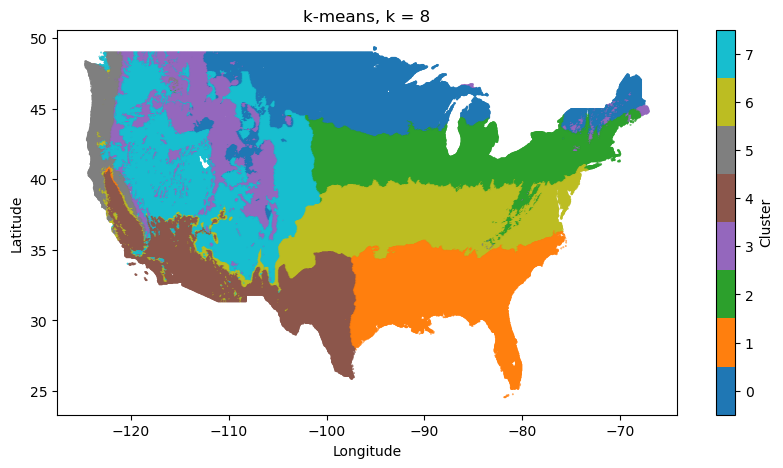

In [40]:
def scatter(ax, labels, title):
    x, y = lon_masked, lat_masked
    k = len(np.unique(labels))
    if k <= 10:
        cmap = plt.get_cmap("tab10", k)
    elif k <= 20:
        cmap = plt.get_cmap("tab20", k)
    sc = ax.scatter(x, y, c=labels, s=0.1, vmin=-0.5, vmax=k-0.5,
               cmap=cmap)
    ax.set(xlabel="Longitude", ylabel="Latitude", title=title)
    return sc

fig, ax = plt.subplots(figsize=(10, 5))
sc = scatter(ax, labels_8, "k-means, k = 8")
fig.colorbar(sc, ax=ax, label = "Cluster")
plt.show()

You can compare the climate zones discovered by the K-Means clustering approach with the map [here](https://www.cec.org/mapmonday/climate-zones-in-north-america/).

_The K-means clustering approach creates similar clusters to the climate zones, with relatively uniform zones east of the Rocky Mountains, stratified by latitude. In the western side, the zones appear to be more dependent on topographic factors like elevation and terrain, with groups varying due to the structure of the mountain ranges resulting in local differences in precipitation and temperature._

13. Repeat parts 11. and 12. but choose a different number of clusters to fit Kmeans. 

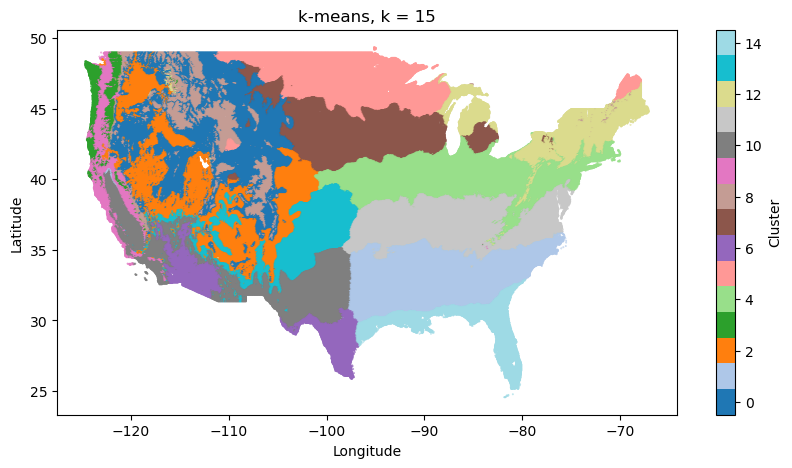

In [41]:
km_15 = KMeans(n_clusters=15, n_init=10, random_state=0).fit(X)
labels_15 = km_15.labels_

fig, ax = plt.subplots(figsize=(10, 5))
sc = scatter(ax, labels_15, "k-means, k = 15")
fig.colorbar(sc, ax=ax, label = "Cluster")
plt.show()

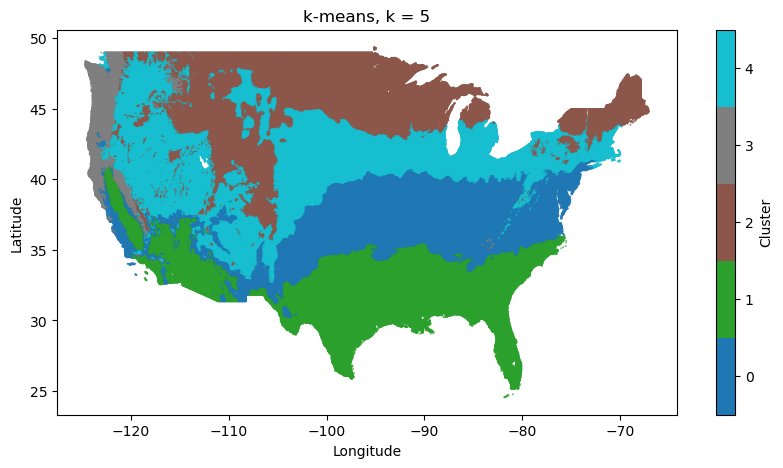

In [42]:
km_5 = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X)
labels_5 = km_5.labels_

fig, ax = plt.subplots(figsize=(10, 5))
sc = scatter(ax, labels_5, "k-means, k = 5")
fig.colorbar(sc, ax=ax, label = "Cluster")
plt.show()

## Part 4: Use a Gaussian Mixture Model to Label Climate Zones

14. Use the `GaussianMixture` method from `sklearn.mixture` to fit 8 components to the `X` feature matrix.

In [43]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=8,random_state=0).fit(X)
gm_labels = gm.predict(X)
resp = gm.predict_proba(X)
gm_confidence = resp.max(axis=1)

In [44]:
gm

,"n_components n_components: int, default=1The number of mixture components.",8
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",0


In [45]:
gm_labels

array([6, 6, 6, ..., 7, 7, 7])

In [46]:
resp

array([[0.0000000e+00, 0.0000000e+00, 6.6510403e-19, ..., 0.0000000e+00,
        1.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 3.1315691e-20, ..., 0.0000000e+00,
        1.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 1.0419742e-18, ..., 0.0000000e+00,
        1.0000000e+00, 0.0000000e+00],
       ...,
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 1.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 1.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 1.0000000e+00]], dtype=float32)

In [47]:
gm_confidence

array([1., 1., 1., ..., 1., 1., 1.], dtype=float32)

15.  Make a scatter plot of `lat_masked` vs. `lon_masked` and color by the components learned by the Gaussian Mixture Model. Set the size of the scatter points to 0.1 and use a colormap that is discrete (rather than continuous).

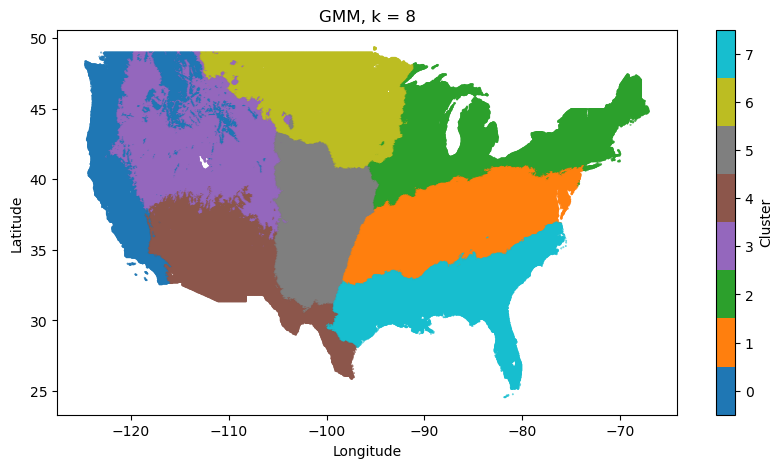

In [48]:
fig, ax = plt.subplots(figsize=(10, 5))
sc = scatter(ax, gm_labels, "GMM, k = 8")
fig.colorbar(sc, ax=ax, label = "Cluster")
plt.show()